In [44]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import os
import json
from PIL import Image, ImageDraw
from tqdm import tqdm
from typing import List
import mercury as mr
import cv2
from pathlib import Path
from scipy.ndimage import sobel, laplace, binary_erosion, binary_fill_holes, label, distance_transform_edt

from MirrorExtractor.simple_mirror_extractor import SimpleMirrorExtractor

In [2]:
def build_mask(gray, thr=0):
    m = gray > thr
    m = binary_fill_holes(m)                 # ciemny piksel wewnątrz lustra wraca
    lab, n = label(m)
    if n > 1:                                # zostaw największy spójny obszar
        sizes = np.bincount(lab.ravel()); sizes[0] = 0
        m = lab == sizes.argmax()
    return m

In [43]:
mirror_extractor = SimpleMirrorExtractor("/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/calibration/points_WebCam.json")

img_path_dir = Path("/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/webcam/2024/05/good/baseline")
crop_array = np.array(crop_list)[:, :, :]
crop_array.shape
img_path_list = sorted(img_path_dir.glob("*.jpg"))
print(img_path_list[:5])

[PosixPath('/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/webcam/2024/05/good/baseline/20240501_1000_la.jpg'), PosixPath('/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/webcam/2024/05/good/baseline/20240501_1010_la.jpg'), PosixPath('/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/webcam/2024/05/good/baseline/20240501_1020_la.jpg'), PosixPath('/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/webcam/2024/05/good/baseline/20240501_1030_la.jpg'), PosixPath('/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/webcam/2024/05/good/baseline/20240501_1040_la.jpg')]


In [55]:
N_IMG = 20
crop_list = [[] for i in range(5)]
for img_path in img_path_list[:N_IMG]:
    img = cv2.imread(str(img_path))
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    for m_id in range(5):
        crop = mirror_extractor.extract_mirror_gray(img_gray, mirror_id=m_id)
        crop_list[m_id].append(crop)

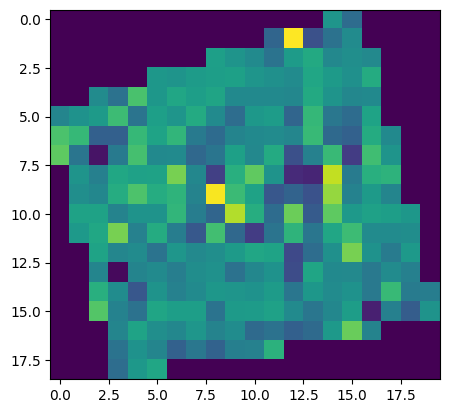

In [70]:
plt.imshow(crop_list[1][0])

In [74]:
print(crop_list[0][0].shape)
print(crop_list[1][0].shape)   
print(crop_list[2][0].shape)  
print(crop_list[3][0].shape) 
print(crop_list[4][0].shape) 

(17, 18)
(19, 20)
(19, 16)
(19, 17)
(19, 16)


In [26]:
mask = build_mask(crop_array[0, :, :])
feat = extract_reference_features(crop_array[16, :, :], m, crop_array[:15, :, :], min_norm=1e-6)

vals = [extract_reference_features(c, m, crop_array[:60, :, :])['ncc_max'] for c in crop_list]
print(np.percentile(vals, [1, 5, 50, 95]))

[0.91253754 0.92983804 1.         1.        ]


In [15]:
crop_array.shape

(112, 20, 17)

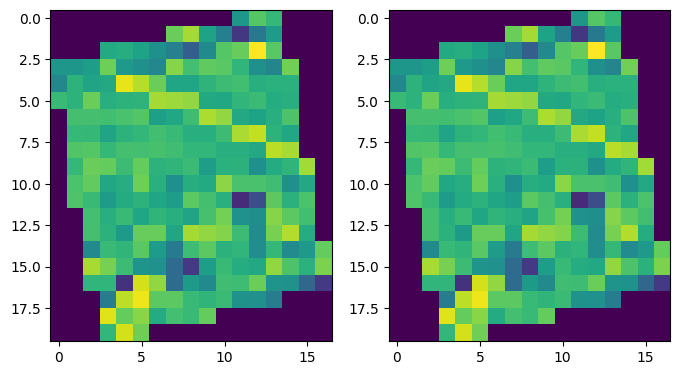

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(8, 5))
img_a = crop_array[0, :, :]
img_b = crop_array[0, :, :]
ax[0].imshow(img_a)
ax[1].imshow(img_b)
plt.show()

Na ile obecny wygląd zwierciadła przypomina to, jak to samo zwierciadło wyglądało wcześniej. 

Miarą podobieństwa jest znormalizowana korelacja wzajemna (normalised cross-correlation, *NCC*), czyli po prostu współczynnik korelacji Pearsona policzony na pikselach.

In [27]:
patch = crop_array[0, :, :]
v = patch[mask].astype(np.float64)   # tylko piksele wewnątrz fasety, spłaszczone do 1D
v -= v.mean()                        # odjęcie średniej
n = np.linalg.norm(v)                # długość euklidesowa wektora

In [29]:
def ncc_pojedyncza(obecna_lat, referencja, maska):
    """Współczynnik korelacji dwóch łatek po pikselach wewnątrz maski."""
    a = obecna_lat[maska].astype(np.float64)
    b = referencja[maska].astype(np.float64)

    a = a - a.mean()
    b = b - b.mean()

    norma_a = np.sqrt(np.sum(a ** 2))
    norma_b = np.sqrt(np.sum(b ** 2))

    if norma_a < 1e-6 or norma_b < 1e-6:
        return np.nan                     # łatka całkowicie płaska

    return float(np.sum(a * b) / (norma_a * norma_b))

def cechy_referencyjne(obecna_lat, maska, bank):
    """bank: tablica (n_ref, H, W) wcześniejszych łatek tej samej fasety."""
    wyniki = []
    for referencja in bank:
        c = ncc_pojedyncza(obecna_lat, referencja, maska)
        if not np.isnan(c):
            wyniki.append(c)

    if len(wyniki) == 0:
        return {'ncc_max': np.nan, 'ncc_med': np.nan}

    return {
        'ncc_max': float(np.max(wyniki)),
        'ncc_med': float(np.median(wyniki)),
    }

In [ ]:
patch = crop_array[0, :, :]
mask = build_mask(patch)

In [28]:
bank = crop_array[:60, :, :]

In [33]:
img_a = crop_array[0, :, :]
img_b = crop_array[5, :, :]
ncc_pojedyncza(img_a, img_b, mask)

0.6715264208822154

In [35]:
cechy_referencyjne(img_a, mask, bank)

{'ncc_max': 0.9999999999999998, 'ncc_med': 0.6708178699355022}

In [72]:
mask = build_mask(crop_list[2][0])
img = crop_list[2][16]
bank = crop_list[2][:15]
cechy_referencyjne(img, mask, bank)

{'ncc_max': 0.7893792348300619, 'ncc_med': 0.6487737162928665}